<a href="https://colab.research.google.com/github/240447-stack/AI-ML/blob/main/AI_ML_(LR).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving test.csv to test (1).csv


First 5 rows:
    x          y
0  77  79.775152
1  21  23.177279
2  22  25.609262
3  20  17.857388
4  36  41.849864

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   x       300 non-null    int64  
 1   y       300 non-null    float64
dtypes: float64(1), int64(1)
memory usage: 4.8 KB
None

Missing Values:
x    0
y    0
dtype: int64

Features:
['x']

Target:
y

Model Evaluation
----------------
R² Score: 0.9908872587629893
Mean Squared Error: 9.259410978631752

Model Coefficients:
  Feature  Coefficient
0       x     1.013495


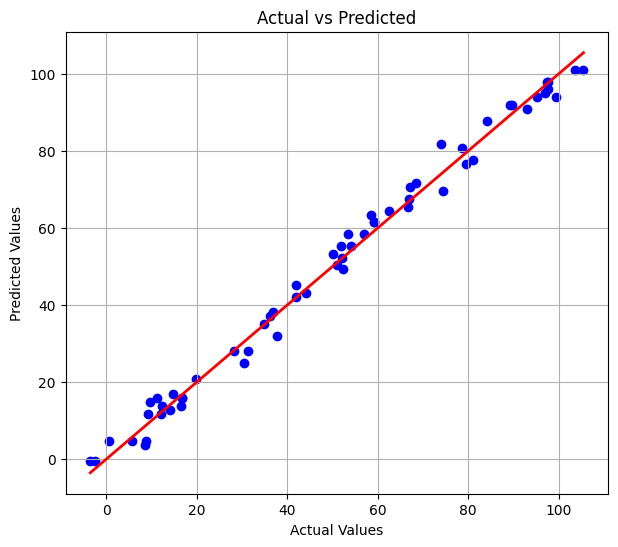

In [ ]:
df = pd.read_csv("test.csv")
print("First 5 rows:")
print(df.head())

print("\nDataset Info:")
print(df.info())

print("\nMissing Values:")
print(df.isnull().sum())

# Remove missing values
df = df.dropna()

# Select only numeric columns
numeric_df = df.select_dtypes(include=np.number)

# Assume the LAST numeric column is the target variable
X = numeric_df.iloc[:, :-1]
y = numeric_df.iloc[:, -1]

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train the Linear Regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict
y_pred = model.predict(X_test)

print("\nModel Evaluation")
print("----------------")
print("R² Score:", r2_score(y_test, y_pred))
print("Mean Squared Error:", mean_squared_error(y_test, y_pred))


coef = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

print("\nModel Coefficients:")
print(coef)

# Actual vs Predicted Plot
plt.figure(figsize=(7,6))
plt.scatter(y_test, y_pred, color='blue')
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()],
         color='red', linewidth=2)
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Actual vs Predicted")
plt.grid(True)
plt.show()

In [ ]:
##uninformed
from collections import deque

graph = {
    'A': ['B', 'C'],
    'B': ['D', 'E'],
    'C': ['F'],
    'D': [],
    'E': ['G'],
    'F': [],
    'G': []
}

def bfs(graph, start, goal):
    queue = deque([[start]])
    visited = set()

    while queue:
        path = queue.popleft()
        node = path[-1]

        if node == goal:
            return path

        if node not in visited:
            visited.add(node)

            for neighbor in graph[node]:
                new_path = list(path)
                new_path.append(neighbor)
                queue.append(new_path)

    return None

print("BFS Path:", bfs(graph, 'A', 'G'))

BFS Path: ['A', 'B', 'E', 'G']


In [ ]:
##informed
import heapq

graph = {
    'A': [('B', 1), ('C', 4)],
    'B': [('D', 2), ('E', 5)],
    'C': [('F', 3)],
    'D': [('G', 3)],
    'E': [('G', 2)],
    'F': [('G', 2)],
    'G': []
}

heuristic = {
    'A': 7,
    'B': 6,
    'C': 4,
    'D': 2,
    'E': 1,
    'F': 2,
    'G': 0
}

def astar(graph, start, goal):
    pq = [(heuristic[start], 0, start, [start])]
    visited = set()

    while pq:
        f, cost, node, path = heapq.heappop(pq)

        if node == goal:
            return path, cost

        if node in visited:
            continue

        visited.add(node)

        for neighbor, weight in graph[node]:
            if neighbor not in visited:
                new_cost = cost + weight
                heapq.heappush(
                    pq,
                    (new_cost + heuristic[neighbor],
                     new_cost,
                     neighbor,
                     path + [neighbor])
                )

    return None

path, cost = astar(graph, 'A', 'G')
print("A* Path:", path)
print("Total Cost:", cost)

A* Path: ['A', 'B', 'D', 'G']
Total Cost: 6
